# 14 · Génération : stratégies d'échantillonnage et décodage spéculatif

**À retenir** — à chaque pas, le modèle donne des logits $z\in\mathbb R^V$ ; le choix du token est une *décision de décodage* indépendante de l'entraînement.

| Méthode | Règle | Effet |
|---|---|---|
| Glouton | $\arg\max_i z_i$ | déterministe, tend à répéter |
| Température $T$ | $p_i=\mathrm{softmax}(z_i/T)$ | $T<1$ plus net, $T>1$ plus aléatoire |
| Top-$k$ | garde les $k$ plus probables | coupe la longue traîne |
| Top-$p$ (noyau) [1] | plus petit ensemble de masse cumulée $\ge p$ | taille adaptative |
| Min-$p$ [2] | garde $p_i\ge p_{\min}\cdot\max_j p_j$ | seuil relatif au meilleur token |
| Pénalité de répétition [3] | $z_i\leftarrow z_i/\theta$ si $z_i>0$, sinon $z_i\theta$, pour les tokens déjà générés | limite les boucles |

**Décodage spéculatif** [4] : un petit modèle *brouillon* propose $\gamma$ tokens, le grand modèle les **vérifie en une seule passe** ; on garde le plus long préfixe validé + 1 token du grand modèle. En glouton, la sortie est **identique** à celle du grand modèle seul.
Nombre moyen de tokens par appel du grand modèle, avec taux d'acceptation i.i.d. $\alpha$ : $\ \dfrac{1-\alpha^{\gamma+1}}{1-\alpha}$.

In [ ]:
import math, time, random
import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(2)

In [ ]:
"""Boîte à outils autonome : copie exacte des modules du paquet `llm` (testés par pytest).
Aucun import de fichier local : tout est défini ici."""

# ===== model/config.py =====
from dataclasses import asdict, dataclass, fields
from typing import Optional


@dataclass
class ModelConfig:
    """Configuration sérialisable d'un Transformer décodeur (GPT-2, LLaMA, Mixtral, DeepSeek...)."""
    # --- dimensions générales ---
    vocab_size: int = 128
    block_size: int = 64          # longueur de contexte d'entraînement
    n_layer: int = 2
    n_head: int = 4
    n_embd: int = 64
    dropout: float = 0.0
    bias: bool = False            # les LLM modernes n'utilisent généralement pas de biais
    tie_weights: bool = True      # partage embedding d'entrée / tête de sortie
    emb_scale: bool = False       # multiplie l'embedding par sqrt(n_embd) (convention du Transformer original ; utile avec positions sinusoïdales)

    # --- position : none | learned | sinusoidal | rope | alibi ---
    position_mode: str = "rope"
    rope_theta: float = 10000.0
    rope_scaling: Optional[str] = None   # None | linear | ntk | yarn
    rope_factor: float = 1.0             # facteur d'extension de contexte s
    rope_orig_len: Optional[int] = None  # longueur d'origine (YaRN) ; défaut = block_size

    # --- normalisation ---
    norm_type: str = "rmsnorm"    # layernorm | rmsnorm
    pre_norm: bool = True         # True = Pre-LN, False = Post-LN
    norm_eps: float = 1e-5
    qk_norm: bool = False         # RMSNorm sur Q et K avant le produit scalaire

    # --- attention : mha | mqa | gqa | mla ---
    attn_type: str = "mha"
    n_kv_head: Optional[int] = None      # GQA : nombre de têtes K/V (mha = n_head, mqa = 1)
    window: Optional[int] = None         # fenêtre glissante (None = attention complète)
    sdpa: bool = False                   # utiliser F.scaled_dot_product_attention
    # MLA (Multi-head Latent Attention, DeepSeek-V2)
    kv_lora_rank: int = 16               # dimension du latent KV compressé
    q_lora_rank: Optional[int] = None    # compression de Q (None = pas de compression)
    rope_head_dim: int = 8               # partie de la tête portant RoPE (clé partagée)

    # --- FFN : relu | gelu | silu | reglu | geglu | swiglu ---
    ffn_type: str = "swiglu"
    ffn_mult: float = 4.0                # largeur cachée = ffn_mult * n_embd (FFN classique)
    ffn_multiple_of: int = 8             # arrondi de la largeur cachée des FFN à porte

    # --- Mixture of Experts ---
    moe: bool = False
    n_experts: int = 8
    top_k: int = 2
    n_shared_experts: int = 0            # experts partagés toujours actifs (DeepSeekMoE)
    expert_hidden: Optional[int] = None  # largeur d'un expert (None = largeur FFN dense)
    router: str = "softmax"              # softmax | sigmoid_bias (sans perte auxiliaire) | expert_choice
    balance_coef: float = 0.01           # coefficient de la perte d'équilibrage (Switch)
    z_loss_coef: float = 0.0             # coefficient de la z-loss du routeur (ST-MoE)
    capacity_factor: Optional[float] = None  # None = pas de capacité (aucun token abandonné)
    n_dense_layers: int = 0              # premières couches restant denses
    bias_update_speed: float = 1e-3      # pas de mise à jour du biais (sigmoid_bias)

    def __post_init__(self):
        if self.n_embd % self.n_head:
            raise ValueError("n_embd doit être divisible par n_head")
        if self.attn_type not in {"mha", "mqa", "gqa", "mla"}:
            raise ValueError(f"attn_type inconnu : {self.attn_type}")
        if self.attn_type == "mha":
            self.n_kv_head = self.n_head
        elif self.attn_type == "mqa":
            self.n_kv_head = 1
        elif self.attn_type == "gqa":
            self.n_kv_head = self.n_kv_head or max(1, self.n_head // 2)
            if self.n_head % self.n_kv_head:
                raise ValueError("n_head doit être divisible par n_kv_head")
        if self.position_mode not in {"none", "learned", "sinusoidal", "rope", "alibi"}:
            raise ValueError(f"position_mode inconnu : {self.position_mode}")
        if self.position_mode == "rope" and self.head_dim % 2 and self.attn_type != "mla":
            raise ValueError("RoPE exige une dimension de tête paire")
        if self.attn_type == "mla" and self.position_mode == "rope" and self.rope_head_dim % 2:
            raise ValueError("rope_head_dim doit être pair")
        if self.norm_type not in {"layernorm", "rmsnorm"}:
            raise ValueError(f"norm_type inconnu : {self.norm_type}")
        if self.ffn_type not in {"relu", "gelu", "silu", "reglu", "geglu", "swiglu"}:
            raise ValueError(f"ffn_type inconnu : {self.ffn_type}")
        if self.router not in {"softmax", "sigmoid_bias", "expert_choice"}:
            raise ValueError(f"router inconnu : {self.router}")
        if self.moe and not (1 <= self.top_k <= self.n_experts):
            raise ValueError("1 <= top_k <= n_experts est requis")

    @property
    def head_dim(self) -> int:
        return self.n_embd // self.n_head

    def to_dict(self) -> dict:
        return asdict(self)

    @classmethod
    def from_dict(cls, data: dict) -> "ModelConfig":
        known = {f.name for f in fields(cls)}
        return cls(**{k: v for k, v in data.items() if k in known})


# ===== model/norms.py =====
import torch
from torch import nn


class LayerNorm(nn.Module):
    r"""LayerNorm : y = (x - mu) / sqrt(sigma^2 + eps) * gamma + beta."""

    def __init__(self, dim: int, eps: float = 1e-5, bias: bool = True):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
        self.bias = nn.Parameter(torch.zeros(dim)) if bias else None

    def forward(self, x):
        mean = x.mean(-1, keepdim=True)
        var = (x - mean).pow(2).mean(-1, keepdim=True)
        y = (x - mean) * torch.rsqrt(var + self.eps) * self.weight
        return y + self.bias if self.bias is not None else y


class RMSNorm(nn.Module):
    r"""RMSNorm : y = x / sqrt(mean(x^2) + eps) * gamma (pas de recentrage, pas de biais)."""

    def __init__(self, dim: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        dtype = x.dtype
        x = x.float()  # statistiques en fp32 pour la stabilité numérique
        y = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return (y * self.weight.float()).to(dtype)


def make_norm(kind: str, dim: int, eps: float = 1e-5, bias: bool = True) -> nn.Module:
    if kind == "layernorm":
        return LayerNorm(dim, eps, bias)
    if kind == "rmsnorm":
        return RMSNorm(dim, eps)
    raise ValueError(f"Normalisation inconnue : {kind}")


# ===== model/positions.py =====
import math
import torch
from torch import nn


def sinusoidal_table(n_pos: int, dim: int) -> torch.Tensor:
    r"""PE(p, 2i) = sin(p / 10000^{2i/d}),  PE(p, 2i+1) = cos(p / 10000^{2i/d})."""
    pos = torch.arange(n_pos, dtype=torch.float32)[:, None]
    div = torch.exp(torch.arange(0, dim, 2, dtype=torch.float32) * (-math.log(10000.0) / dim))
    table = torch.zeros(n_pos, dim)
    table[:, 0::2] = torch.sin(pos * div)
    table[:, 1::2] = torch.cos(pos * div)[:, : dim // 2]
    return table


class AbsolutePositions(nn.Module):
    """Positions absolues ajoutées aux embeddings : « learned » ou « sinusoidal »."""

    def __init__(self, kind: str, max_len: int, dim: int):
        super().__init__()
        self.kind, self.max_len = kind, max_len
        if kind == "learned":
            self.emb = nn.Embedding(max_len, dim)
        else:
            self.register_buffer("table", sinusoidal_table(max_len, dim), persistent=False)

    def forward(self, x, start_pos: int = 0):
        t = x.size(1)
        if start_pos + t > self.max_len:
            raise ValueError(f"Position {start_pos + t} > longueur maximale {self.max_len} (positions absolues)")
        pos = torch.arange(start_pos, start_pos + t, device=x.device)
        pe = self.emb(pos) if self.kind == "learned" else self.table[pos].to(x.dtype)
        return x + pe[None]


def rope_inv_freq(dim: int, theta: float = 10000.0, scaling=None, factor: float = 1.0,
                  orig_len: int = 64, alpha: float = 1.0, beta: float = 32.0):
    r"""Fréquences RoPE  theta_i = theta^{-2i/d}  avec extension de contexte optionnelle.

    - ``linear`` (Position Interpolation) : positions divisées par s.
    - ``ntk``    (NTK-aware)              : base theta' = theta * s^{d/(d-2)}.
    - ``yarn``   (YaRN)                   : interpolation par bande de fréquences + facteur de température.
    Retourne (inv_freq, mscale) ; mscale multiplie cos/sin (température d'attention de YaRN).
    """
    inv = 1.0 / (theta ** (torch.arange(0, dim, 2, dtype=torch.float32) / dim))
    mscale = 1.0
    if scaling is None or factor == 1.0:
        return inv, mscale
    if scaling == "linear":
        return inv / factor, mscale
    if scaling == "ntk":
        new_theta = theta * factor ** (dim / (dim - 2))
        return 1.0 / (new_theta ** (torch.arange(0, dim, 2, dtype=torch.float32) / dim)), mscale
    if scaling == "yarn":
        rotations = orig_len * inv / (2 * math.pi)            # nombre de tours sur la longueur d'origine
        gamma = ((rotations - alpha) / (beta - alpha)).clamp(0.0, 1.0)  # 0 = interpoler, 1 = garder
        inv = (1 - gamma) * inv / factor + gamma * inv
        return inv, 0.1 * math.log(factor) + 1.0
    raise ValueError(f"rope_scaling inconnu : {scaling}")


def rotate_half(x):
    x1, x2 = x[..., : x.shape[-1] // 2], x[..., x.shape[-1] // 2:]
    return torch.cat((-x2, x1), dim=-1)


def apply_rope(x, positions, inv_freq, mscale: float = 1.0):
    r"""Applique la rotation de RoPE à ``x`` de forme (..., T, d) ; ``positions`` de forme (T,).

    Convention « moitiés » (LLaMA/HF) : la paire (i, i + d/2) est tournée de l'angle p * theta_i.
    """
    angles = positions.float()[:, None] * inv_freq.to(x.device)[None, :]
    emb = torch.cat((angles, angles), dim=-1)
    cos, sin = emb.cos() * mscale, emb.sin() * mscale
    return (x * cos.to(x.dtype)) + (rotate_half(x) * sin.to(x.dtype))


def alibi_slopes(n_head: int) -> torch.Tensor:
    r"""Pentes géométriques m_h = 2^{-8h/n} (h = 1..n), généralisées aux n non puissances de 2."""
    def power_of_2(n):
        start = 2 ** (-8.0 / n)
        return [start ** (i + 1) for i in range(n)]
    if math.log2(n_head).is_integer():
        return torch.tensor(power_of_2(n_head))
    closest = 2 ** math.floor(math.log2(n_head))
    extra = power_of_2(2 * closest)[0::2][: n_head - closest]
    return torch.tensor(power_of_2(closest) + extra)


def alibi_bias(slopes, q_pos, k_pos):
    r"""Biais additif ALiBi : -m_h * (i - j) pour j <= i. Forme (H, Tq, Tk)."""
    dist = (q_pos[:, None] - k_pos[None, :]).clamp(min=0).float()
    return -slopes[:, None, None].to(dist.device) * dist[None]


# ===== model/cache.py =====
import torch


class KVCache:
    """Cache par couche. Chaque couche stocke un dictionnaire de tenseurs concaténés le long du temps.

    - attention MHA/MQA/GQA : ``k`` et ``v`` de forme (B, H_kv, T, d), ``dim=2``.
    - attention MLA         : ``c`` (latent, B, T, r) et ``kr`` (clé RoPE, B, T, d_r), ``dim=1``.
    ``n_seen`` compte les tokens déjà traités : c'est la position absolue du prochain token.
    """

    def __init__(self, n_layer: int, window=None):
        self.layers = [None] * n_layer
        self.n_seen = 0
        self.window = window

    def update(self, layer: int, dim: int, **tensors):
        old = self.layers[layer]
        full = {k: (v if old is None else torch.cat([old[k], v], dim=dim)) for k, v in tensors.items()}
        stored = full
        if self.window is not None:  # cache roulant : on ne conserve que les `window` derniers tokens
            stored = {k: v.narrow(dim, max(0, v.size(dim) - self.window), min(v.size(dim), self.window))
                      for k, v in full.items()}
        self.layers[layer] = stored
        return full  # la requête courante voit tout ce qui vient d'être concaténé

    def length(self, layer: int = 0) -> int:
        entry = self.layers[layer]
        if entry is None:
            return 0
        first = next(iter(entry.values()))
        return first.size(2 if first.dim() == 4 else 1)

    def nbytes(self) -> int:
        return sum(v.numel() * v.element_size() for e in self.layers if e for v in e.values())


# ===== model/attention.py =====
import math
import torch
import torch.nn.functional as F
from torch import nn



def build_bias(q_pos, k_pos, window=None, slopes=None, dtype=torch.float32):
    """Biais additif (Tq, Tk) ou (H, Tq, Tk) : -inf hors masque causal/fenêtre, ALiBi éventuel."""
    allowed = k_pos[None, :] <= q_pos[:, None]
    if window is not None:
        allowed &= (q_pos[:, None] - k_pos[None, :]) < window
    bias = torch.zeros(allowed.shape, dtype=dtype, device=q_pos.device).masked_fill(~allowed, float("-inf"))
    if slopes is not None:
        bias = bias[None] + alibi_bias(slopes, q_pos, k_pos).to(dtype)
    return bias


def attend(q, k, v, bias, scale, dropout_p=0.0, training=False, use_sdpa=False):
    """softmax(q k^T * scale + bias) v ; q: (B,H,Tq,dq), k: (B,H,Tk,dq), v: (B,H,Tk,dv)."""
    if use_sdpa:
        return F.scaled_dot_product_attention(q, k, v, attn_mask=bias.to(q.dtype), dropout_p=dropout_p if training else 0.0, scale=scale)
    scores = (q @ k.transpose(-2, -1)) * scale + bias
    weights = torch.softmax(scores.float(), dim=-1).to(q.dtype)
    weights = F.dropout(weights, dropout_p, training)
    return weights @ v


class GroupedQueryAttention(nn.Module):
    """MHA (n_kv_head = n_head), GQA (1 < n_kv_head < n_head) et MQA (n_kv_head = 1) en une seule classe."""

    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg
        self.n_head, self.n_kv, self.hd = cfg.n_head, cfg.n_kv_head, cfg.head_dim
        self.q_proj = nn.Linear(cfg.n_embd, self.n_head * self.hd, bias=cfg.bias)
        self.k_proj = nn.Linear(cfg.n_embd, self.n_kv * self.hd, bias=cfg.bias)
        self.v_proj = nn.Linear(cfg.n_embd, self.n_kv * self.hd, bias=cfg.bias)
        self.out_proj = nn.Linear(self.n_head * self.hd, cfg.n_embd, bias=cfg.bias)
        self.q_norm = RMSNorm(self.hd, cfg.norm_eps) if cfg.qk_norm else None
        self.k_norm = RMSNorm(self.hd, cfg.norm_eps) if cfg.qk_norm else None
        self.use_rope = cfg.position_mode == "rope"
        if self.use_rope:
            orig = cfg.rope_orig_len or cfg.block_size
            inv, self.mscale = rope_inv_freq(self.hd, cfg.rope_theta, cfg.rope_scaling, cfg.rope_factor, orig)
            self.register_buffer("inv_freq", inv, persistent=False)
        if cfg.position_mode == "alibi":
            self.register_buffer("slopes", alibi_slopes(self.n_head), persistent=False)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, cache=None, layer=0, start_pos=0):
        b, t, _ = x.shape
        q = self.q_proj(x).view(b, t, self.n_head, self.hd).transpose(1, 2)
        k = self.k_proj(x).view(b, t, self.n_kv, self.hd).transpose(1, 2)
        v = self.v_proj(x).view(b, t, self.n_kv, self.hd).transpose(1, 2)
        if self.q_norm is not None:
            q, k = self.q_norm(q), self.k_norm(k)
        q_pos = torch.arange(start_pos, start_pos + t, device=x.device)
        if self.use_rope:
            q = apply_rope(q, q_pos, self.inv_freq, self.mscale)
            k = apply_rope(k, q_pos, self.inv_freq, self.mscale)  # K est mis en cache APRÈS rotation
        if cache is not None:
            full = cache.update(layer, 2, k=k, v=v)
            k, v = full["k"], full["v"]
        tk = k.size(2)
        k_pos = torch.arange(start_pos + t - tk, start_pos + t, device=x.device)
        if self.n_kv != self.n_head:  # partage des têtes K/V entre groupes de requêtes
            rep = self.n_head // self.n_kv
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        bias = build_bias(q_pos, k_pos, self.cfg.window, getattr(self, "slopes", None), q.dtype)
        out = attend(q, k, v, bias, 1.0 / math.sqrt(self.hd), self.cfg.dropout, self.training, self.cfg.sdpa)
        return self.drop(self.out_proj(out.transpose(1, 2).reshape(b, t, -1)))


class MultiHeadLatentAttention(nn.Module):
    """MLA (DeepSeek-V2) : K et V sont reconstruits depuis un latent c_KV de dimension r ;
    seuls c_KV (r) et la clé RoPE partagée (d_r) sont mis en cache, soit r + d_r valeurs par token."""

    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg
        self.n_head, self.hd = cfg.n_head, cfg.head_dim
        self.r = cfg.kv_lora_rank
        self.use_rope = cfg.position_mode == "rope"
        self.dr = cfg.rope_head_dim if self.use_rope else 0
        d = cfg.n_embd
        if cfg.q_lora_rank:
            self.q_down = nn.Linear(d, cfg.q_lora_rank, bias=False)
            self.q_norm = RMSNorm(cfg.q_lora_rank, cfg.norm_eps)
            self.q_up = nn.Linear(cfg.q_lora_rank, self.n_head * (self.hd + self.dr), bias=False)
        else:
            self.q_up = nn.Linear(d, self.n_head * (self.hd + self.dr), bias=False)
            self.q_down = None
        self.kv_down = nn.Linear(d, self.r, bias=False)         # W^{DKV}
        self.kv_norm = RMSNorm(self.r, cfg.norm_eps)
        self.k_up = nn.Linear(self.r, self.n_head * self.hd, bias=False)  # W^{UK}
        self.v_up = nn.Linear(self.r, self.n_head * self.hd, bias=False)  # W^{UV}
        if self.use_rope:
            self.k_rope = nn.Linear(d, self.dr, bias=False)     # clé RoPE partagée entre les têtes
            inv, self.mscale = rope_inv_freq(self.dr, cfg.rope_theta, cfg.rope_scaling, cfg.rope_factor,
                                             cfg.rope_orig_len or cfg.block_size)
            self.register_buffer("inv_freq", inv, persistent=False)
        if cfg.position_mode == "alibi":
            self.register_buffer("slopes", alibi_slopes(self.n_head), persistent=False)
        self.out_proj = nn.Linear(self.n_head * self.hd, d, bias=False)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, cache=None, layer=0, start_pos=0):
        b, t, _ = x.shape
        H, hd, dr = self.n_head, self.hd, self.dr
        q_in = self.q_norm(self.q_down(x)) if self.q_down is not None else x
        q = self.q_up(q_in).view(b, t, H, hd + dr).transpose(1, 2)
        q_nope, q_rope = q[..., :hd], q[..., hd:]
        c = self.kv_norm(self.kv_down(x))                         # (B, T, r) : ce qu'on met en cache
        kr = self.k_rope(x) if self.use_rope else None            # (B, T, dr)
        q_pos = torch.arange(start_pos, start_pos + t, device=x.device)
        if self.use_rope:
            q_rope = apply_rope(q_rope, q_pos, self.inv_freq, self.mscale)
            kr = apply_rope(kr, q_pos, self.inv_freq, self.mscale)
        if cache is not None:
            tensors = {"c": c} if kr is None else {"c": c, "kr": kr}
            full = cache.update(layer, 1, **tensors)
            c, kr = full["c"], full.get("kr")
        tk = c.size(1)
        k_pos = torch.arange(start_pos + t - tk, start_pos + t, device=x.device)
        k_nope = self.k_up(c).view(b, tk, H, hd).transpose(1, 2)  # reconstruction de K depuis le latent
        v = self.v_up(c).view(b, tk, H, hd).transpose(1, 2)
        if self.use_rope:
            k = torch.cat([k_nope, kr[:, None].expand(b, H, tk, dr)], dim=-1)
            q = torch.cat([q_nope, q_rope], dim=-1)
        else:
            k, q = k_nope, q_nope
        bias = build_bias(q_pos, k_pos, self.cfg.window, getattr(self, "slopes", None), q.dtype)
        out = attend(q, k, v, bias, 1.0 / math.sqrt(hd + dr), self.cfg.dropout, self.training, self.cfg.sdpa)
        return self.drop(self.out_proj(out.transpose(1, 2).reshape(b, t, -1)))


def make_attention(cfg: ModelConfig) -> nn.Module:
    return MultiHeadLatentAttention(cfg) if cfg.attn_type == "mla" else GroupedQueryAttention(cfg)


def kv_cache_floats_per_token(cfg: ModelConfig) -> int:
    """Nombre de valeurs mises en cache par token et par couche (formule théorique)."""
    if cfg.attn_type == "mla":
        return cfg.kv_lora_rank + (cfg.rope_head_dim if cfg.position_mode == "rope" else 0)
    return 2 * cfg.n_kv_head * cfg.head_dim


# ===== model/ffn.py =====
import torch.nn.functional as F
from torch import nn


ACT = {"relu": F.relu, "gelu": F.gelu, "silu": F.silu, "reglu": F.relu, "geglu": F.gelu, "swiglu": F.silu}
GATED = {"reglu", "geglu", "swiglu"}


def ffn_hidden(cfg: ModelConfig) -> int:
    """Largeur cachée. Variantes à porte : 2/3 de la largeur classique pour conserver ~ le même nombre de paramètres."""
    if cfg.ffn_type in GATED:
        h = int(2 * cfg.ffn_mult * cfg.n_embd / 3)
        m = cfg.ffn_multiple_of
        return ((h + m - 1) // m) * m
    return int(cfg.ffn_mult * cfg.n_embd)


class FeedForward(nn.Module):
    r"""Classique : W2 act(W1 x).   À porte : W2 (act(W_gate x) ⊙ W_up x)."""

    def __init__(self, cfg: ModelConfig, hidden: int = None):
        super().__init__()
        hidden = hidden or ffn_hidden(cfg)
        self.gated = cfg.ffn_type in GATED
        self.act = ACT[cfg.ffn_type]
        self.up = nn.Linear(cfg.n_embd, hidden, bias=cfg.bias)
        self.gate = nn.Linear(cfg.n_embd, hidden, bias=cfg.bias) if self.gated else None
        self.down = nn.Linear(hidden, cfg.n_embd, bias=cfg.bias)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        h = self.act(self.gate(x)) * self.up(x) if self.gated else self.act(self.up(x))
        return self.drop(self.down(h))


# ===== model/moe.py =====
import math
import torch
import torch.nn.functional as F
from torch import nn



class MoE(nn.Module):
    """Couche MoE remplaçant le FFN. ``forward`` renvoie (sortie, perte_auxiliaire) ;
    les statistiques de charge sont dans ``self.stats`` (détachées du graphe)."""

    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg
        hidden = cfg.expert_hidden or ffn_hidden(cfg)
        self.router = nn.Linear(cfg.n_embd, cfg.n_experts, bias=False)
        self.experts = nn.ModuleList([FeedForward(cfg, hidden) for _ in range(cfg.n_experts)])
        self.shared = nn.ModuleList([FeedForward(cfg, hidden) for _ in range(cfg.n_shared_experts)])
        self.register_buffer("route_bias", torch.zeros(cfg.n_experts), persistent=True)
        self.stats = {}

    def forward(self, x):
        cfg = self.cfg
        b, t, d = x.shape
        flat = x.reshape(-1, d)
        n_tok = flat.size(0)
        logits = self.router(flat).float()                                  # (N, E)
        aux = flat.new_zeros(())
        if cfg.router == "expert_choice":
            out, load, dropped = self._expert_choice(flat, logits)
        else:
            if cfg.router == "softmax":
                probs = logits.softmax(-1)
                top_w, top_i = probs.topk(cfg.top_k, dim=-1)
                top_w = top_w / top_w.sum(-1, keepdim=True)                 # renormalisation (Mixtral)
            else:  # sigmoid_bias : le biais sert à SÉLECTIONNER, pas à pondérer (DeepSeek-V3)
                scores = logits.sigmoid()
                top_i = (scores + self.route_bias).topk(cfg.top_k, dim=-1).indices
                top_w = scores.gather(-1, top_i)
                top_w = top_w / top_w.sum(-1, keepdim=True)
                probs = scores / scores.sum(-1, keepdim=True)
            out, load, dropped = self._dispatch(flat, top_i, top_w)
            if self.training and cfg.router == "softmax" and cfg.balance_coef > 0:
                # Switch : E * sum_e f_e * P_e   (f = part de tokens envoyés à e, P = probabilité moyenne)
                f = load / max(1, n_tok * cfg.top_k)
                aux = aux + cfg.balance_coef * cfg.n_experts * (f.detach() * probs.mean(0)).sum()
            if self.training and cfg.router == "sigmoid_bias":
                with torch.no_grad():   # sous-chargé -> biais augmente ; surchargé -> biais diminue
                    err = load.mean() - load
                    self.route_bias += cfg.bias_update_speed * torch.sign(err)
        if self.training and cfg.z_loss_coef > 0:
            aux = aux + cfg.z_loss_coef * torch.logsumexp(logits, dim=-1).pow(2).mean()
        for s in self.shared:
            out = out + s(flat)
        self.stats = {"load": (load / load.sum().clamp(min=1)).detach(), "dropped": float(dropped)}
        return out.view(b, t, d), aux

    def _dispatch(self, flat, top_i, top_w):
        cfg, n_tok = self.cfg, flat.size(0)
        out = torch.zeros_like(flat)
        load = torch.zeros(cfg.n_experts, device=flat.device)
        cap = None if cfg.capacity_factor is None else math.ceil(cfg.capacity_factor * n_tok * cfg.top_k / cfg.n_experts)
        n_dropped = 0
        for e, expert in enumerate(self.experts):
            tok, slot = (top_i == e).nonzero(as_tuple=True)
            if cap is not None and tok.numel() > cap:       # capacité dépassée : les derniers tokens sont abandonnés
                n_dropped += tok.numel() - cap
                tok, slot = tok[:cap], slot[:cap]
            load[e] = tok.numel()
            if tok.numel():
                out.index_add_(0, tok, expert(flat[tok]) * top_w[tok, slot, None].to(flat.dtype))
        return out, load, n_dropped / max(1, n_tok * self.cfg.top_k)

    def _expert_choice(self, flat, logits):
        """Chaque expert choisit ses c meilleurs tokens : charge parfaitement équilibrée,
        mais NON causal (le choix dépend des autres tokens du lot) -> inadapté au décodage autorégressif."""
        cfg, n_tok = self.cfg, flat.size(0)
        cap = max(1, int(n_tok * cfg.top_k / cfg.n_experts))
        probs = logits.softmax(-1)
        w, idx = probs.t().topk(cap, dim=-1)                # (E, c)
        out = torch.zeros_like(flat)
        for e, expert in enumerate(self.experts):
            out.index_add_(0, idx[e], expert(flat[idx[e]]) * w[e, :, None].to(flat.dtype))
        covered = torch.zeros(n_tok, device=flat.device)
        covered[idx.reshape(-1)] = 1.0
        load = torch.full((cfg.n_experts,), float(cap), device=flat.device)
        return out, load, 1.0 - covered.mean().item()       # « dropped » = tokens sans aucun expert


# ===== model/block.py =====
from torch import nn



class Block(nn.Module):
    def __init__(self, cfg: ModelConfig, layer_idx: int):
        super().__init__()
        self.cfg, self.layer_idx = cfg, layer_idx
        self.norm1 = make_norm(cfg.norm_type, cfg.n_embd, cfg.norm_eps, cfg.bias)
        self.norm2 = make_norm(cfg.norm_type, cfg.n_embd, cfg.norm_eps, cfg.bias)
        self.attn = make_attention(cfg)
        self.is_moe = cfg.moe and layer_idx >= cfg.n_dense_layers
        self.ffn = MoE(cfg) if self.is_moe else FeedForward(cfg)
        self.drop = nn.Dropout(cfg.dropout)

    def _ffn(self, x):
        if self.is_moe:
            return self.ffn(x)
        return self.ffn(x), x.new_zeros(())

    def forward(self, x, cache=None, start_pos=0):
        if self.cfg.pre_norm:   # x + F(norm(x)) : chemin résiduel « propre »
            x = x + self.drop(self.attn(self.norm1(x), cache, self.layer_idx, start_pos))
            y, aux = self._ffn(self.norm2(x))
            return x + self.drop(y), aux
        x = self.norm1(x + self.drop(self.attn(x, cache, self.layer_idx, start_pos)))  # Post-LN
        y, aux = self._ffn(x)
        return self.norm2(x + self.drop(y)), aux


# ===== model/model.py =====
import math
from typing import NamedTuple, Optional

import torch
import torch.nn.functional as F
from torch import nn



class Output(NamedTuple):
    logits: torch.Tensor
    loss: Optional[torch.Tensor]      # entropie croisée seule (comparable entre modèles)
    aux_loss: torch.Tensor            # pertes auxiliaires MoE (équilibrage, z-loss)


class LM(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.pos = AbsolutePositions(cfg.position_mode, cfg.block_size, cfg.n_embd) \
            if cfg.position_mode in ("learned", "sinusoidal") else None
        self.blocks = nn.ModuleList([Block(cfg, i) for i in range(cfg.n_layer)])
        self.final_norm = make_norm(cfg.norm_type, cfg.n_embd, cfg.norm_eps, cfg.bias)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.drop = nn.Dropout(cfg.dropout)
        self.apply(self._init)
        for name, p in self.named_parameters():   # init GPT-2 : sorties résiduelles / sqrt(2 L)
            if name.endswith("out_proj.weight") or name.endswith("down.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * cfg.n_layer))
        if cfg.tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)
            if getattr(m, "bias", None) is not None:
                nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None, cache: Optional[KVCache] = None) -> Output:
        b, t = idx.shape
        start = cache.n_seen if cache is not None else 0
        if cache is None and t > self.cfg.block_size and self.cfg.position_mode in ("learned", "sinusoidal"):
            raise ValueError("Séquence plus longue que block_size (positions absolues)")
        x = self.tok_emb(idx)
        if self.cfg.emb_scale:
            x = x * math.sqrt(self.cfg.n_embd)
        if self.pos is not None:
            x = self.pos(x, start)
        x = self.drop(x)
        aux = x.new_zeros(())
        for blk in self.blocks:
            x, a = blk(x, cache, start)
            aux = aux + a
        if cache is not None:
            cache.n_seen += t
        logits = self.lm_head(self.final_norm(x))
        loss = None if targets is None else F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return Output(logits, loss, aux)

    # --- utilitaires ---
    def num_parameters(self, active_only: bool = False) -> int:
        """Paramètres uniques. ``active_only`` : compte seulement top_k experts (+ partagés) par couche MoE."""
        total = sum(p.numel() for p in self.parameters())
        if active_only and self.cfg.moe:
            for blk in self.blocks:
                if blk.is_moe:
                    per = sum(p.numel() for p in blk.ffn.experts[0].parameters())
                    total -= per * (self.cfg.n_experts - self.cfg.top_k)
        return total

    def new_cache(self) -> KVCache:
        return KVCache(self.cfg.n_layer, self.cfg.window)

    def moe_stats(self):
        return [b.ffn.stats for b in self.blocks if b.is_moe]


# ===== training/optimizers.py =====
r"""Optimiseurs écrits à la main (SGD, RMSprop, Adagrad, Adam, AdamW, Lion, Muon).

Notation : g_t gradient, theta_t paramètres, eta le taux d'apprentissage, lambda le weight decay.
Chaque classe documente sa règle de mise à jour ; les tests comparent SGD/Adam/AdamW à torch.optim.
"""
import torch
from torch.optim import Optimizer


class SGD(Optimizer):
    r"""SGD avec momentum (Polyak) ou Nesterov ; le weight decay est de type L2 (ajouté au gradient).

    g <- g + lambda*theta ;  v <- mu*v + g ;  theta <- theta - eta * v
    Nesterov : theta <- theta - eta * (g + mu*v).
    """

    def __init__(self, params, lr=1e-2, momentum=0.0, nesterov=False, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, nesterov=nesterov, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            for p in g["params"]:
                if p.grad is None:
                    continue
                d = p.grad
                if g["weight_decay"]:
                    d = d + g["weight_decay"] * p
                if g["momentum"]:
                    st = self.state[p]
                    buf = st.setdefault("v", torch.zeros_like(p))
                    buf.mul_(g["momentum"]).add_(d)
                    d = d + g["momentum"] * buf if g["nesterov"] else buf
                p.add_(d, alpha=-g["lr"])


class RMSprop(Optimizer):
    r"""s <- alpha*s + (1-alpha) g^2 ;  theta <- theta - eta * g / (sqrt(s) + eps)."""

    def __init__(self, params, lr=1e-3, alpha=0.99, eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, alpha=alpha, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            for p in g["params"]:
                if p.grad is None:
                    continue
                d = p.grad + g["weight_decay"] * p if g["weight_decay"] else p.grad
                s = self.state[p].setdefault("s", torch.zeros_like(p))
                s.mul_(g["alpha"]).addcmul_(d, d, value=1 - g["alpha"])
                p.addcdiv_(d, s.sqrt().add_(g["eps"]), value=-g["lr"])


class Adagrad(Optimizer):
    r"""G <- G + g^2 ;  theta <- theta - eta * g / (sqrt(G) + eps)."""

    def __init__(self, params, lr=1e-2, eps=1e-10, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            for p in g["params"]:
                if p.grad is None:
                    continue
                d = p.grad + g["weight_decay"] * p if g["weight_decay"] else p.grad
                G = self.state[p].setdefault("G", torch.zeros_like(p))
                G.addcmul_(d, d)
                p.addcdiv_(d, G.sqrt().add_(g["eps"]), value=-g["lr"])


class Adam(Optimizer):
    r"""Adam ; ``decoupled=False`` -> L2 classique, ``decoupled=True`` -> AdamW (weight decay découplé).

    m <- b1 m + (1-b1) g ;  v <- b2 v + (1-b2) g^2
    m^ = m/(1-b1^t) ;  v^ = v/(1-b2^t)
    Adam  : g <- g + lambda*theta AVANT les moments.
    AdamW : theta <- theta - eta*lambda*theta  À PART, puis  theta <- theta - eta * m^/(sqrt(v^)+eps).
    """

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0, decoupled=False):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, decoupled=decoupled))

    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            b1, b2 = g["betas"]
            for p in g["params"]:
                if p.grad is None:
                    continue
                st = self.state[p]
                if not st:
                    st.update(t=0, m=torch.zeros_like(p), v=torch.zeros_like(p))
                st["t"] += 1
                d = p.grad
                if g["weight_decay"] and not g["decoupled"]:
                    d = d + g["weight_decay"] * p
                st["m"].mul_(b1).add_(d, alpha=1 - b1)
                st["v"].mul_(b2).addcmul_(d, d, value=1 - b2)
                m_hat = st["m"] / (1 - b1 ** st["t"])
                v_hat = st["v"] / (1 - b2 ** st["t"])
                if g["weight_decay"] and g["decoupled"]:
                    p.mul_(1 - g["lr"] * g["weight_decay"])
                p.addcdiv_(m_hat, v_hat.sqrt().add_(g["eps"]), value=-g["lr"])


class AdamW(Adam):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01):
        super().__init__(params, lr, betas, eps, weight_decay, decoupled=True)


class Lion(Optimizer):
    r"""Lion (Chen et al. 2023) : update = sign(b1 m + (1-b1) g) ;  m <- b2 m + (1-b2) g.
    theta <- theta - eta (update + lambda theta). Prendre lr ~ 3-10x plus petit qu'AdamW."""

    def __init__(self, params, lr=1e-4, betas=(0.9, 0.99), weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            b1, b2 = g["betas"]
            for p in g["params"]:
                if p.grad is None:
                    continue
                m = self.state[p].setdefault("m", torch.zeros_like(p))
                update = (b1 * m + (1 - b1) * p.grad).sign()
                p.add_(update + g["weight_decay"] * p, alpha=-g["lr"])
                m.mul_(b2).add_(p.grad, alpha=1 - b2)


def newton_schulz(G, steps=5, eps=1e-7):
    r"""Orthogonalise G (approximation de U V^T de sa SVD) par itération de Newton-Schulz quintique."""
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G.float()
    X = X / (X.norm() + eps)
    transposed = X.size(0) > X.size(1)
    if transposed:
        X = X.t()
    for _ in range(steps):
        A = X @ X.t()
        X = a * X + (b * A + c * A @ A) @ X
    return X.t() if transposed else X


class Muon(Optimizer):
    r"""Muon (Jordan 2024) pour les matrices 2D des couches cachées : momentum puis orthogonalisation.

    m <- mu m + g ;  update = NS(g + mu m) ;  theta <- theta - eta * scale * update
    scale = 0.2 sqrt(max(n, m)) (Liu et al. 2025) aligne le RMS de l'update sur celui d'AdamW.
    Les autres paramètres (embeddings, normes, vecteurs) doivent utiliser AdamW (groupe distinct).
    """

    def __init__(self, params, lr=2e-2, momentum=0.95, weight_decay=0.0, ns_steps=5, match_adamw_rms=True):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay,
                                      ns_steps=ns_steps, match_adamw_rms=match_adamw_rms))

    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            for p in g["params"]:
                if p.grad is None:
                    continue
                if p.ndim != 2:
                    raise ValueError("Muon ne s'applique qu'aux matrices 2D")
                buf = self.state[p].setdefault("m", torch.zeros_like(p))
                buf.mul_(g["momentum"]).add_(p.grad)
                upd = newton_schulz(p.grad + g["momentum"] * buf, g["ns_steps"]).to(p.dtype)
                if g["match_adamw_rms"]:
                    upd = upd * 0.2 * max(p.shape) ** 0.5
                p.mul_(1 - g["lr"] * g["weight_decay"])
                p.add_(upd, alpha=-g["lr"])


OPTIMIZERS = ("sgd", "sgd_momentum", "nesterov", "rmsprop", "adagrad", "adam", "adamw", "lion", "muon")


def split_decay(model):
    """Sépare les paramètres : matrices (decay) / biais, normes, embeddings (sans decay)."""
    decay, no_decay = [], []
    seen = set()
    for n, p in model.named_parameters():
        if not p.requires_grad or id(p) in seen:
            continue
        seen.add(id(p))
        is_matrix = p.ndim >= 2 and "emb" not in n and "norm" not in n and "route_bias" not in n
        (decay if is_matrix else no_decay).append((n, p))
    return decay, no_decay


def build_optimizer(model, name="adamw", lr=3e-4, weight_decay=0.1, betas=(0.9, 0.95), eps=1e-8,
                    momentum=0.9, muon_lr=None):
    """Fabrique un optimiseur avec groupes decay/no-decay (le weight decay ne s'applique pas aux normes/biais/embeddings)."""
    name = name.lower()
    decay, no_decay = split_decay(model)
    d, nd = [p for _, p in decay], [p for _, p in no_decay]
    if name == "muon":  # Muon sur les matrices cachées, AdamW sur le reste
        hidden = [p for n, p in decay if "lm_head" not in n]
        rest = [p for n, p in decay if "lm_head" in n] + nd
        opt = Muon(hidden, lr=muon_lr or lr * 10, weight_decay=weight_decay)
        opt2 = AdamW(rest, lr=lr, betas=betas, eps=eps, weight_decay=0.0)
        return _Combined(opt, opt2)
    groups = [{"params": d, "weight_decay": weight_decay}, {"params": nd, "weight_decay": 0.0}]
    if name in ("sgd", "sgd_momentum", "nesterov"):
        mom = 0.0 if name == "sgd" else momentum
        return SGD(groups, lr=lr, momentum=mom, nesterov=name == "nesterov")
    if name == "rmsprop":
        return RMSprop(groups, lr=lr, eps=eps)
    if name == "adagrad":
        return Adagrad(groups, lr=lr)
    if name == "adam":
        return Adam(groups, lr=lr, betas=betas, eps=eps)
    if name == "adamw":
        return AdamW(groups, lr=lr, betas=betas, eps=eps)
    if name == "lion":
        return Lion(groups, lr=lr, betas=(0.9, 0.99))
    raise ValueError(f"Optimiseur inconnu : {name} (choix : {OPTIMIZERS})")


class _Combined:
    """Enveloppe deux optimiseurs (ex. Muon + AdamW) derrière l'interface habituelle."""

    def __init__(self, *opts):
        self.opts = opts
        self.param_groups = [g for o in opts for g in o.param_groups]

    def zero_grad(self, set_to_none=True):
        for o in self.opts:
            o.zero_grad(set_to_none=set_to_none)

    def step(self):
        for o in self.opts:
            o.step()

    def state_dict(self):
        return {"opts": [o.state_dict() for o in self.opts]}

    def load_state_dict(self, sd):
        for o, s in zip(self.opts, sd["opts"]):
            o.load_state_dict(s)


# ===== training/schedules.py =====
r"""Schedules de taux d'apprentissage : facteur multiplicatif f(t) tel que eta_t = eta_max * f(t)."""
import math

SCHEDULES = ("constant", "linear", "cosine", "warmup_cosine", "warmup_linear", "inv_sqrt", "wsd")


def lr_factor(name: str, step: int, total: int, warmup: int = 0, min_ratio: float = 0.1, decay_frac: float = 0.2) -> float:
    """``step`` commence à 0. Le warmup linéaire (step+1)/warmup s'applique à tous les schedules « warmup_* », inv_sqrt et wsd."""
    if name not in SCHEDULES:
        raise ValueError(f"Schedule inconnu : {name} (choix : {SCHEDULES})")
    if name == "constant":
        return 1.0
    if name == "linear":
        return 1.0 - (1.0 - min_ratio) * min(1.0, step / max(1, total))
    if name == "cosine":
        return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * min(1.0, step / max(1, total))))
    if step < warmup:
        return (step + 1) / max(1, warmup)
    if name == "inv_sqrt":
        return math.sqrt(max(1, warmup) / (step + 1))
    if name == "wsd":  # Warmup - Stable - Decay (MiniCPM) : plateau puis décroissance finale
        decay_start = int(total * (1 - decay_frac))
        if step < decay_start:
            return 1.0
        p = min(1.0, (step - decay_start) / max(1, total - decay_start))
        return min_ratio + (1 - min_ratio) * (1 - p)
    p = min(1.0, (step - warmup) / max(1, total - warmup))
    if name == "warmup_linear":
        return 1.0 - (1.0 - min_ratio) * p
    return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * p))  # warmup_cosine


# ===== training/trainer.py =====
import contextlib
import copy
import math
import time
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Callable, Optional

import numpy as np
import torch



@dataclass
class TrainConfig:
    # budget
    steps: int = 200
    batch_size: int = 16
    grad_accum: int = 1               # micro-lots accumulés avant chaque mise à jour
    block_size: Optional[int] = None  # défaut : model.cfg.block_size
    # optimisation
    optimizer: str = "adamw"          # sgd | sgd_momentum | nesterov | rmsprop | adagrad | adam | adamw | lion | muon
    lr: float = 3e-3
    weight_decay: float = 0.1
    betas: tuple = (0.9, 0.95)
    eps: float = 1e-8
    momentum: float = 0.9
    grad_clip: Optional[float] = 1.0
    # schedule
    schedule: str = "warmup_cosine"   # constant | linear | cosine | warmup_cosine | warmup_linear | inv_sqrt | wsd
    warmup_steps: int = 20
    min_lr_ratio: float = 0.1
    decay_frac: float = 0.2           # WSD : part finale du budget consacrée à la décroissance
    # numérique / performance
    dtype: str = "float32"            # float32 | bfloat16 | float16 (autocast)
    compile: bool = False             # torch.compile (nécessite un compilateur C++)
    grad_checkpointing: bool = False  # recalcul des blocs pendant la rétropropagation (économise la mémoire)
    z_loss: float = 0.0               # PaLM : coef * mean(logsumexp(logits)^2)
    label_smoothing: float = 0.0
    ema_decay: Optional[float] = None # moyenne mobile exponentielle des poids (évaluée à la place du modèle)
    # suivi
    eval_interval: int = 50
    eval_iters: int = 10
    log_interval: int = 0             # 0 = pas de log ; sinon affiche toutes les n étapes
    early_stop_patience: Optional[int] = None   # nombre d'évaluations sans amélioration de la val
    # persistance
    checkpoint: Optional[str] = None
    save_best_only: bool = True
    resume: bool = False
    seed: int = 0
    device: str = "auto"

    def to_dict(self):
        return asdict(self)


def get_batch(tokens: torch.Tensor, batch_size: int, block_size: int, device, gen: Optional[torch.Generator] = None):
    """Fenêtres aléatoires (x, y) avec y = x décalé d'un token."""
    ix = torch.randint(0, len(tokens) - block_size - 1, (batch_size,), generator=gen)
    x = torch.stack([tokens[i:i + block_size] for i in ix])
    y = torch.stack([tokens[i + 1:i + 1 + block_size] for i in ix])
    return x.to(device), y.to(device)


@torch.no_grad()
def evaluate(model, tokens, batch_size, block_size, iters, device, seed: int = 1234):
    """Perte de validation sur des lots FIXES (même seed => mêmes lots pour tous les modèles comparés)."""
    was_training = model.training
    model.eval()
    gen = torch.Generator().manual_seed(seed)
    losses = []
    for _ in range(iters):
        x, y = get_batch(tokens, batch_size, block_size, device, gen)
        losses.append(model(x, y).loss.item())
    model.train(was_training)
    return float(np.mean(losses))


class EMA:
    def __init__(self, model, decay):
        self.decay, self.shadow = decay, copy.deepcopy(model).eval()
        for p in self.shadow.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for s, p in zip(self.shadow.parameters(), model.parameters()):
            s.mul_(self.decay).add_(p.detach(), alpha=1 - self.decay)


def _autocast(dtype: str, device: str):
    if dtype == "float32":
        return contextlib.nullcontext()
    return torch.autocast(device_type="cuda" if device.startswith("cuda") else "cpu",
                          dtype=torch.bfloat16 if dtype == "bfloat16" else torch.float16)


def train(model, train_tokens, val_tokens, cfg: TrainConfig, callback: Optional[Callable] = None):
    """Entraîne ``model`` et renvoie un dictionnaire ``history`` (listes alignées) + résumé final."""
    device = ("cuda" if torch.cuda.is_available() else "cpu") if cfg.device == "auto" else cfg.device
    torch.manual_seed(cfg.seed)
    gen = torch.Generator().manual_seed(cfg.seed)
    model.to(device).train()
    block = cfg.block_size or model.cfg.block_size
    train_tokens, val_tokens = torch.as_tensor(train_tokens), torch.as_tensor(val_tokens)
    opt = build_optimizer(model, cfg.optimizer, cfg.lr, cfg.weight_decay, cfg.betas, cfg.eps, cfg.momentum)
    base_lrs = [g["lr"] for g in opt.param_groups]
    scaler = torch.amp.GradScaler("cuda") if cfg.dtype == "float16" and device.startswith("cuda") else None
    fwd = torch.compile(model) if cfg.compile else model
    if cfg.grad_checkpointing:
        from torch.utils.checkpoint import checkpoint
        for blk in model.blocks:
            blk._orig_forward = blk.forward
            blk.forward = (lambda f: (lambda x, cache=None, start_pos=0: checkpoint(f, x, cache, start_pos, use_reentrant=False)))(blk._orig_forward)
    ema = EMA(model, cfg.ema_decay) if cfg.ema_decay else None

    start, best, bad_evals = 0, float("inf"), 0
    hist = {k: [] for k in ("step", "train_loss", "val_loss", "grad_norm", "lr", "tokens_per_s", "aux_loss", "elapsed")}
    if cfg.resume and cfg.checkpoint and Path(cfg.checkpoint).exists():
        ck = torch.load(cfg.checkpoint, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["optimizer"])
        start, best, hist = ck["step"], ck.get("best", best), ck.get("history", hist)
        if ema and ck.get("ema"):
            ema.shadow.load_state_dict(ck["ema"])
        if ck.get("data_rng") is not None:
            gen.set_state(ck["data_rng"].cpu())   # les lots suivants sont ceux qu'aurait vus l'entraînement continu
        print(f"Reprise à l'étape {start}")

    t0, tok_count, run_loss, run_n, run_aux = time.perf_counter(), 0, 0.0, 0, 0.0
    eval_model = ema.shadow if ema else model
    for step in range(start, cfg.steps):
        f = lr_factor(cfg.schedule, step, cfg.steps, cfg.warmup_steps, cfg.min_lr_ratio, cfg.decay_frac)
        for g, base in zip(opt.param_groups, base_lrs):
            g["lr"] = base * f
        opt.zero_grad(set_to_none=True)
        for _ in range(cfg.grad_accum):
            x, y = get_batch(train_tokens, cfg.batch_size, block, device, gen)
            with _autocast(cfg.dtype, device):
                out = fwd(x, y)
                loss = out.loss
                if cfg.label_smoothing > 0:
                    lp = out.logits.float().log_softmax(-1)
                    smooth = -lp.mean(-1).mean()
                    loss = (1 - cfg.label_smoothing) * loss + cfg.label_smoothing * smooth
                if cfg.z_loss > 0:
                    loss = loss + cfg.z_loss * torch.logsumexp(out.logits.float(), -1).pow(2).mean()
                total = (loss + out.aux_loss) / cfg.grad_accum
            (scaler.scale(total) if scaler else total).backward()
            run_loss += out.loss.item(); run_aux += float(out.aux_loss.detach()); run_n += 1
            tok_count += x.numel()
        if scaler:
            scaler.unscale_(opt)
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip if cfg.grad_clip else float("inf"))
        if scaler:
            scaler.step(opt); scaler.update()
        else:
            opt.step()
        if ema:
            ema.update(model)
        s = step + 1
        if cfg.log_interval and s % cfg.log_interval == 0:
            print(f"étape {s:5d} | perte {run_loss / run_n:.4f} | |g| {float(gn):.2f} | lr {opt.param_groups[0]['lr']:.2e}")
        if s % cfg.eval_interval == 0 or s == cfg.steps or s == 1:
            v = evaluate(eval_model, val_tokens, cfg.batch_size, block, cfg.eval_iters, device)
            el = time.perf_counter() - t0
            for k, val in zip(hist, (s, run_loss / run_n, v, float(gn), opt.param_groups[0]["lr"],
                                     tok_count / max(el, 1e-9), run_aux / run_n, el)):
                hist[k].append(val)
            run_loss, run_n, run_aux = 0.0, 0, 0.0
            if callback:
                callback(s, hist)
            improved = v < best
            best = min(best, v)
            bad_evals = 0 if improved else bad_evals + 1
            if cfg.checkpoint and (improved or not cfg.save_best_only):
                Path(cfg.checkpoint).parent.mkdir(parents=True, exist_ok=True)
                torch.save({"model": model.state_dict(), "ema": ema.shadow.state_dict() if ema else None,
                            "optimizer": opt.state_dict(), "step": s, "best": best, "data_rng": gen.get_state(),
                            "history": hist, "config": model.cfg.to_dict(), "train_config": cfg.to_dict()}, cfg.checkpoint)
            if cfg.early_stop_patience and bad_evals >= cfg.early_stop_patience:
                print(f"Arrêt anticipé à l'étape {s}")
                break
    if cfg.grad_checkpointing:
        for blk in model.blocks:
            blk.forward = blk._orig_forward
    hist["final_val_loss"] = hist["val_loss"][-1]
    hist["best_val_loss"] = best
    hist["params"] = model.num_parameters()
    hist["active_params"] = model.num_parameters(active_only=True)
    hist["ema_model"] = ema.shadow if ema else None
    return hist


# ===== training/compare.py =====
import math
import time

import numpy as np
import torch



def compare(variants, data, base_model=None, base_train=None, seeds=(0, 1), verbose=True, keep_models=False):
    """``variants`` : {nom: {"model": {...}, "train": {...}}} (ou directement des champs de ModelConfig).
    ``data`` : (train_tokens, val_tokens, vocab_size). Retourne {nom: résultats} et affiche un tableau.
    Les champs de ``variants`` écrasent ``base_model`` / ``base_train`` ; seul le facteur testé doit changer."""
    tr, va, vocab = data
    results = {}
    for name, spec in variants.items():
        spec = spec if ("model" in spec or "train" in spec) else {"model": spec}
        mkw = {**(base_model or {}), **spec.get("model", {})}
        tkw = {**(base_train or {}), **spec.get("train", {})}
        runs, models = [], []
        for seed in seeds:
            torch.manual_seed(seed)
            model = LM(ModelConfig(vocab_size=vocab, **mkw))
            t0 = time.perf_counter()
            h = train(model, tr, va, TrainConfig(seed=seed, device="cpu", **tkw))
            h["wall"] = time.perf_counter() - t0
            h.pop("ema_model", None)
            runs.append(h); models.append(model if keep_models else None)
        vals = np.array([r["final_val_loss"] for r in runs])
        results[name] = dict(runs=runs, mean=vals.mean(), std=vals.std(ddof=1) if len(vals) > 1 else float("nan"),
                             params=runs[0]["params"], active=runs[0]["active_params"],
                             tok_s=float(np.mean([r["tokens_per_s"][-1] for r in runs])),
                             model_kw=mkw, train_kw=tkw, models=models)
    if verbose:
        table(results)
    return results


def table(results, ref=None):
    """Tableau : perte de validation (moy ± std), bits/token, écart à la référence, paramètres, débit."""
    ref = ref or next(iter(results))
    print(f"{'variante':<26}{'val (moy±std)':>18}{'bits/tok':>9}{'Δ vs réf':>10}{'params':>10}{'actifs':>10}{'tok/s':>9}")
    best = min(r["mean"] for r in results.values())
    for name, r in results.items():
        d = r["mean"] - results[ref]["mean"]
        star = " *" if r["mean"] == best else ""
        print(f"{name:<26}{r['mean']:>10.4f} ±{r['std']:.4f}{r['mean'] / math.log(2):>9.3f}{d:>+10.4f}{r['params']:>10,}{r['active']:>10,}{r['tok_s']:>9.0f}{star}")
    print("(* = meilleure moyenne ; un écart inférieur à ~2 écarts-types n'est pas concluant avec si peu de seeds)")


def plot_curves(results, key="val_loss", ax=None, title=None):
    import matplotlib.pyplot as plt
    ax = ax or plt.subplots(figsize=(6.5, 3.6))[1]
    for name, r in results.items():
        steps = r["runs"][0]["step"]
        arr = np.array([run[key] for run in r["runs"]])
        m = arr.mean(0)
        ax.plot(steps, m, marker="o", ms=3, label=name)
        if len(arr) > 1:
            ax.fill_between(steps, arr.min(0), arr.max(0), alpha=0.15)
    ax.set_xlabel("étape"); ax.set_ylabel(key); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    if title:
        ax.set_title(title)
    return ax


# ===== generation/sampling.py =====
import torch


def apply_repetition_penalty(logits, generated, penalty: float):
    """Pénalise les tokens déjà générés (Keskar et al., 2019) : logit/penalty si > 0, logit*penalty sinon."""
    if penalty == 1.0 or generated.numel() == 0:
        return logits
    logits = logits.clone()
    for b in range(logits.size(0)):
        ids = generated[b].unique()
        sel = logits[b, ids]
        logits[b, ids] = torch.where(sel > 0, sel / penalty, sel * penalty)
    return logits


def filter_logits(logits, top_k=None, top_p=None, min_p=None):
    """Masque (-inf) les candidats exclus par top-k, top-p (noyau) et min-p."""
    if top_k:
        k = min(int(top_k), logits.size(-1))
        logits = logits.masked_fill(logits < torch.topk(logits, k, dim=-1).values[..., -1, None], -torch.inf)
    if min_p:
        probs = logits.softmax(-1)
        logits = logits.masked_fill(probs < min_p * probs.max(-1, keepdim=True).values, -torch.inf)
    if top_p and 0 < top_p < 1:
        sl, si = torch.sort(logits, descending=True, dim=-1)
        cum = sl.softmax(-1).cumsum(-1)
        remove = cum - sl.softmax(-1) > top_p      # on garde le premier token qui dépasse p
        logits = logits.masked_fill(torch.zeros_like(remove).scatter(-1, si, remove), -torch.inf)
    return logits


def sample_next_token(logits, temperature=1.0, top_k=None, top_p=None, min_p=None, greedy=False, generator=None):
    if greedy or temperature == 0:
        return logits.argmax(-1, keepdim=True)
    logits = filter_logits(logits / temperature, top_k, top_p, min_p)
    return torch.multinomial(logits.softmax(-1), 1, generator=generator)


# ===== generation/generate.py =====
import torch



@torch.no_grad()
def generate(model, idx, max_new_tokens, temperature=1.0, top_k=None, top_p=None, min_p=None, greedy=False,
             repetition_penalty=1.0, use_cache=True, generator=None, eos_id=None):
    """Étend ``idx`` (B, T). Avec ``use_cache`` : préremplissage du prompt puis un token à la fois (O(T) par pas)."""
    model.eval()
    cache = model.new_cache() if use_cache else None
    cur = idx
    for _ in range(max_new_tokens):
        if use_cache:
            inp = cur if cache.n_seen == 0 else cur[:, -1:]
            logits = model(inp, cache=cache).logits[:, -1]
        else:
            logits = model(cur[:, -model.cfg.block_size:]).logits[:, -1]
        logits = apply_repetition_penalty(logits, cur, repetition_penalty)
        nxt = sample_next_token(logits, temperature, top_k, top_p, min_p, greedy, generator)
        cur = torch.cat([cur, nxt], dim=1)
        if eos_id is not None and bool((nxt == eos_id).all()):
            break
    return cur


# ===== data/synthetic.py =====
import random

SUJ = [("le chat", "s"), ("le chien", "s"), ("la petite fille", "s"), ("l'ingénieur", "s"), ("le modèle", "s"),
       ("les chats", "p"), ("les chiens", "p"), ("les enfants", "p"), ("les chercheurs", "p"), ("les modèles", "p")]
VERBE = {"s": ["mange", "observe", "cherche", "apprend", "prédit", "regarde"],
         "p": ["mangent", "observent", "cherchent", "apprennent", "prédisent", "regardent"]}
OBJ = ["une pomme", "le texte", "la lune", "un exemple", "la réponse", "un petit jardin", "le signal"]
REL = {"s": "qui dort", "p": "qui dorment"}
ADV = ["souvent", "toujours", "rarement", "ici", "demain", "lentement"]
COND = ["il pleut", "le vent souffle", "la nuit tombe", "le modèle converge"]
CONS = ["on reste au calme", "on sort dehors", "la perte diminue", "on relit le texte"]


def _phrase(rng):
    suj, nb = rng.choice(SUJ)
    r = rng.random()
    if r < 0.35:
        return f"{suj} {rng.choice(VERBE[nb])} {rng.choice(OBJ)} {rng.choice(ADV)}."
    if r < 0.6:  # accord à travers une relative : « les chats qui dorment mangent »
        return f"{suj} {REL[nb]} {rng.choice(VERBE[nb])} {rng.choice(OBJ)}."
    if r < 0.8:
        return f"si {rng.choice(COND)}, alors {rng.choice(CONS)}."
    inner, nb2 = rng.choice(SUJ)  # parenthèse à refermer
    return f"{suj} {rng.choice(VERBE[nb])} ({inner} {rng.choice(VERBE[nb2])}) {rng.choice(ADV)}."


def make_corpus(n_chars: int = 200_000, seed: int = 0) -> str:
    rng = random.Random(seed)
    out, size = [], 0
    while size < n_chars:
        s = _phrase(rng)
        out.append(s)
        size += len(s) + 1
    return "\n".join(out)

## 1. Effet de chaque filtre sur une distribution jouet

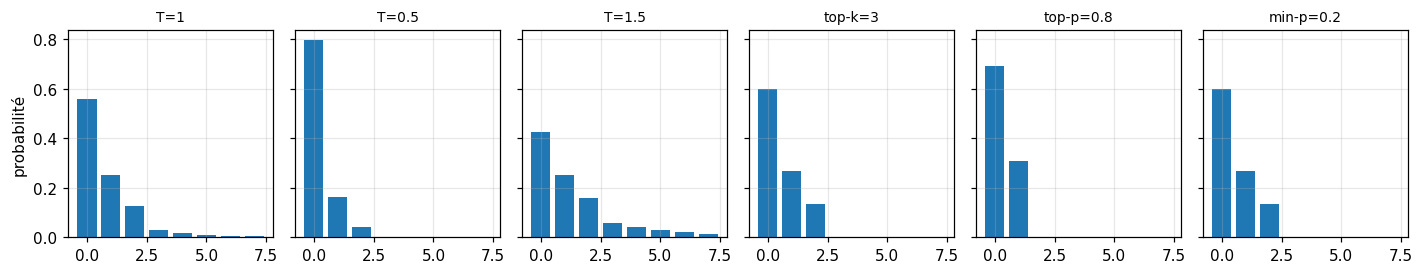

In [3]:
logits = torch.tensor([[4.0, 3.2, 2.5, 1.0, 0.5, 0.0, -0.5, -1.0]])
reglages = {"T=1": dict(), "T=0.5": dict(T=0.5), "T=1.5": dict(T=1.5), "top-k=3": dict(top_k=3), "top-p=0.8": dict(top_p=0.8), "min-p=0.2": dict(min_p=0.2)}
fig, ax = plt.subplots(1, len(reglages), figsize=(13, 2.6), sharey=True)
for a, (nom, kw) in zip(ax, reglages.items()):
    z = logits / kw.get("T", 1.0); p = filter_logits(z, kw.get("top_k"), kw.get("top_p"), kw.get("min_p")).softmax(-1)[0]
    a.bar(range(8), p.numpy()); a.set_title(nom, fontsize=9)
ax[0].set_ylabel("probabilité"); plt.tight_layout(); plt.show()

## 2. Un modèle entraîné et un **vérificateur de grammaire**
Le corpus synthétique étant engendré par une grammaire, on peut **mesurer objectivement** la qualité d'une phrase générée : est-elle grammaticalement valide (accords, parenthèses, motif si/alors) ? Cela donne une métrique de qualité sans juge humain, à comparer à la **diversité** (part de phrases distinctes).

In [4]:
# Corpus synthétique français (grammaire probabiliste) -> tokens caractère. Reproductible, sans téléchargement.
# Pour utiliser votre propre texte : TEXTE = open("mon_corpus.txt", encoding="utf-8").read()
TEXTE = make_corpus(150_000, seed=0)
CHARS = sorted(set(TEXTE)); STOI = {c: i for i, c in enumerate(CHARS)}
IDS = torch.tensor([STOI[c] for c in TEXTE]); N = int(0.9 * len(IDS))
TRAIN, VAL, VOCAB = IDS[:N], IDS[N:], len(CHARS)
DATA = (TRAIN, VAL, VOCAB)
print(f"{len(TEXTE):,} caractères | vocabulaire {VOCAB} | train {len(TRAIN):,} | val {len(VAL):,}")
print(TEXTE[:150])

150,031 caractères | vocabulaire 31 | train 135,027 | val 15,004
si le modèle converge, alors on reste au calme.
le modèle apprend (les enfants cherchent) ici.
les chats qui dorment observent la réponse.
la petite f


In [5]:
import re
# Modèle cible plus grand et entraîné plus longtemps (~5 min sur 1 cœur CPU) : un modèle sous-entraîné produit des non-mots et fausse toute évaluation de génération.
BASE_M = dict(block_size=64, n_layer=3, n_head=4, n_embd=96)
BASE_T = dict(steps=1500, batch_size=32, lr=3e-3, warmup_steps=50, eval_interval=750, eval_iters=10)
res = compare({"LM": dict()}, DATA, BASE_M, BASE_T, seeds=(0,), keep_models=True)
lm = res["LM"]["models"][0].eval()

def alt(xs): return "(?:" + "|".join(re.escape(x) for x in xs) + ")"
patrons = []
for nb in "sp":
    sujs = alt([s for s, n in SUJ if n == nb]); v = alt(VERBE[nb])
    patrons += [f"{sujs} {v} {alt(OBJ)} {alt(ADV)}\\.", f"{sujs} {re.escape(REL[nb])} {v} {alt(OBJ)}\\."]
    for nb2 in "sp":
        patrons.append(f"{sujs} {v} \\({alt([s for s, n in SUJ if n == nb2])} {alt(VERBE[nb2])}\\) {alt(ADV)}\\.")
patrons.append(f"si {alt(COND)}, alors {alt(CONS)}\\.")
VALIDE = re.compile("|".join(patrons))
verif = [VALIDE.fullmatch(s) is not None for s in TEXTE.split("\n")[:2000]]
print(f"contrôle du vérificateur : {100*np.mean(verif):.1f}% des phrases du corpus d'entraînement sont valides (attendu : 100%)")

variante                       val (moy±std) bits/tok  Δ vs réf    params    actifs    tok/s
LM                            0.2436 ±nan    0.351   +0.0000   335,424   335,424    11796 *
(* = meilleure moyenne ; un écart inférieur à ~2 écarts-types n'est pas concluant avec si peu de seeds)
contrôle du vérificateur : 100.0% des phrases du corpus d'entraînement sont valides (attendu : 100%)


In [6]:
def evaluer(reglage, n_seq=24, n_tok=300, seed=0):
    g = torch.Generator().manual_seed(seed); prompt = torch.full((n_seq, 1), STOI["\n"])
    out = generate(lm, prompt, n_tok, generator=g, **reglage)
    phrases = []
    for seq in out.tolist():
        txt = "".join(CHARS[i] for i in seq).split("\n")[1:-1]      # on retire la première/dernière phrase (tronquées)
        phrases += [s for s in txt if s]
    ok = [VALIDE.fullmatch(s) is not None for s in phrases]
    valides = [s for s, o in zip(phrases, ok) if o]
    invalides = [s for s, o in zip(phrases, ok) if not o]
    return dict(n=len(phrases), valide=100 * np.mean(ok), distinct=100 * len(set(phrases)) / max(1, len(phrases)),
                distinct_valides=100 * len(set(valides)) / max(1, len(valides)), invalides=invalides)

REGLAGES = {"glouton": dict(greedy=True), "T=0.7": dict(temperature=0.7), "T=1.0": dict(temperature=1.0), "T=1.3": dict(temperature=1.3),
            "T=1.0 top-k=5": dict(temperature=1.0, top_k=5), "T=1.0 top-p=0.9": dict(temperature=1.0, top_p=0.9), "T=1.0 min-p=0.05": dict(temperature=1.0, min_p=0.05),
            "T=1.3 top-p=0.9": dict(temperature=1.3, top_p=0.9), "T=1.3 min-p=0.1": dict(temperature=1.3, min_p=0.1), "T=1.0 pénalité 1.3": dict(temperature=1.0, repetition_penalty=1.3)}
print(f"{'réglage':22}{'phrases':>9}{'valides %':>11}{'distinctes %':>14}{'distinctes/valides %':>22}")
resultats = {}
for nom, kw in REGLAGES.items():
    r = evaluer(kw); resultats[nom] = r; print(f"{nom:22}{r['n']:>9}{r['valide']:>11.1f}{r['distinct']:>14.1f}{r['distinct_valides']:>22.1f}")

réglage                 phrases  valides %  distinctes %  distinctes/valides %


glouton                      96       50.0           4.2                   4.2


T=0.7                        93       45.2          95.7                  92.9


T=1.0                       102       44.1          96.1                  91.1


T=1.3                       109       34.9          96.3                  89.5


...

T=1.0 top-p=0.9             119       41.2          95.0                  89.8


T=1.0 min-p=0.05            109       45.0          95.4                  89.8


T=1.3 top-p=0.9             113       38.9          93.8                  88.6


T=1.3 min-p=0.1             117       38.5          94.9                  88.9


T=1.0 pénalité 1.3           99       38.4          94.9                  86.8


Exemples de phrases INVALIDES (T=1.0) :
   'les chats observent (la petite textee cherche la réponse le textente chents cherchent) ra lun prédie unexexts cherchent.'
   'si le vent souffle, alors on sort des calme.'
   'le chat cherche un petit jaurdiens mangent chent (lentit la nuil de souve.'
   'la réple tun pe lexte.'
   'lors la rsigéples préditunegalonvent.'
   'sien rarexent qui dordèlentenfant la répples rapplercherchent quie textententeut.'


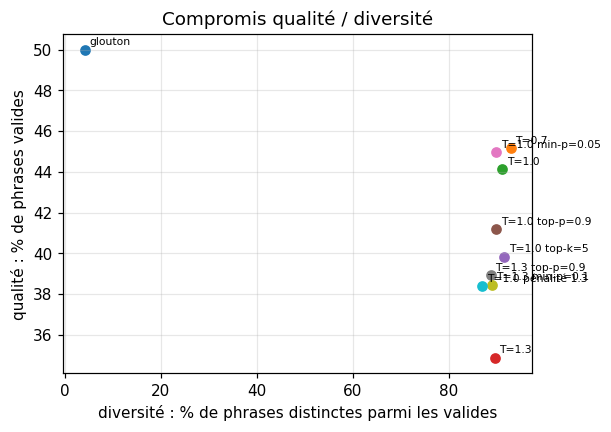

In [7]:
print("Exemples de phrases INVALIDES (T=1.0) :"); [print("  ", repr(s)) for s in resultats["T=1.0"]["invalides"][:6]]
plt.figure(figsize=(5.5, 4))
for nom, r in resultats.items(): plt.scatter(r["distinct_valides"], r["valide"]); plt.annotate(nom, (r["distinct_valides"], r["valide"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.xlabel("diversité : % de phrases distinctes parmi les valides"); plt.ylabel("qualité : % de phrases valides"); plt.title("Compromis qualité / diversité"); plt.show()

**Lecture (exécution fournie)** : même le glouton ne produit qu'environ la moitié de phrases valides : le modèle (335 k paramètres, 1 500 pas) **n'a pas totalement appris la grammaire** ; les exemples de phrases invalides ci-dessus montrent le type d'erreur. La validité **baisse** quand la température augmente ($T=1{,}3$ : ≈ 35 %) ; top-$p$/min-$p$/top-$k$ limitent peu cette baisse ici (écarts de quelques points, avec ~100 phrases par réglage : erreur d'échantillonnage de l'ordre de ±5 points, donc **non concluants**). Le glouton a une diversité minimale (peu de phrases distinctes). La colonne *distinctes* seule est trompeuse (les phrases invalides sont presque toutes uniques) ; d'où la colonne *distinctes parmi les valides*.

## 3. Décodage spéculatif : correction et gain
On entraîne un petit modèle brouillon (1 couche, $d=48$) et on vérifie que la sortie du décodage spéculatif glouton **égale** celle du modèle cible ; on mesure le taux d'acceptation et le nombre de tokens par appel de la cible.

In [8]:
resb = compare({"brouillon": dict(n_layer=1, n_embd=48)}, DATA, BASE_M, BASE_T, seeds=(0,), keep_models=True, verbose=False)
draft = resb["brouillon"]["models"][0].eval()
print("paramètres cible / brouillon :", lm.num_parameters(), "/", draft.num_parameters(), "| val brouillon :", round(resb["brouillon"]["mean"], 3))

@torch.no_grad()
def spec_greedy(target, draft, prompt, n_new, gamma):
    cur = prompt.clone(); calls = 0; acc = 0; prop = 0
    while cur.size(1) - prompt.size(1) < n_new:
        d = cur.clone(); props = []
        for _ in range(gamma):
            nxt = draft(d).logits[:, -1].argmax(-1, keepdim=True); props.append(nxt); d = torch.cat([d, nxt], 1)
        props = torch.cat(props, 1)
        tgt = target(d).logits[:, cur.size(1) - 1:].argmax(-1); calls += 1     # UNE passe de la cible pour gamma+1 positions
        n_ok = 0
        while n_ok < gamma and props[0, n_ok] == tgt[0, n_ok]: n_ok += 1
        acc += n_ok; prop += gamma
        cur = torch.cat([cur, props[:, :n_ok], tgt[:, n_ok:n_ok + 1]], 1)
    return cur[:, :prompt.size(1) + n_new], calls, acc / prop

prompt = torch.tensor([[STOI["\n"]]]); N_NEW = 120
# Référence à CONTEXTE COMPLET : avec use_cache=False, generate() rogne le contexte aux block_size derniers tokens, ce qui divergerait au-delà de 64 tokens.
ref = generate(lm, prompt, N_NEW, greedy=True, use_cache=True)
print(f"{'γ':>3}{'sortie identique':>34}{'α mesuré':>10}{'tokens/appel cible':>20}{'théorie (α iid)':>17}")
for gamma in (1, 2, 4, 8):
    out, calls, alpha = spec_greedy(lm, draft, prompt, N_NEW, gamma)
    theo = (1 - alpha ** (gamma + 1)) / (1 - alpha) if alpha < 1 else gamma + 1
    commun = int((out[0] != ref[0]).nonzero()[0]) if not torch.equal(out, ref) else N_NEW + 1
    print(f"{gamma:>3}{str(torch.equal(out, ref)) + ' (préfixe commun ' + str(commun) + ')':>34}{alpha:>10.2f}{N_NEW / calls:>20.2f}{theo:>17.2f}")

paramètres cible / brouillon : 335424 / 29280 | val brouillon : 0.254


  γ                  sortie identique  α mesuré  tokens/appel cible  théorie (α iid)


  1         True (préfixe commun 121)      0.82                1.82             1.82


  2         True (préfixe commun 121)      0.78                2.55             2.38


  4         True (préfixe commun 121)      0.66                3.64             2.57


  8         True (préfixe commun 121)      0.50                5.00             2.00


**Lecture** : la colonne « sortie identique » valide l'implémentation *si* elle vaut `True` (le décodage spéculatif glouton ne change pas le texte). Si elle vaut `False`, le préfixe commun indique où l'écart apparaît ; il peut venir d'une différence numérique entre passes de longueurs différentes qui bascule un argmax quasi-égal (le modèle n'est pas parfaitement entraîné). Le nombre de tokens par appel de la cible dépasse 1 tant que le brouillon est souvent d'accord ; le gain réel en temps dépend du rapport de coût brouillon/cible (non mesuré : la vérification est implémentée sans cache KV). **Dans l'exécution fournie, la sortie est identique pour tous les γ** (validation de l'implémentation) et le nombre de tokens par appel mesuré **dépasse** la formule i.i.d. dès γ=4 (3,64 vs 2,57 ; 5,0 vs 2,0 pour γ=8) : l'acceptation est fortement *corrélée* entre positions (quand le brouillon est dans une phrase bien formée, il a presque toujours raison), ce que la formule i.i.d. ignore.

## Bilan
| Objectif | Réglage typique |
|---|---|
| Sortie factuelle/déterministe | glouton ou $T\le0.3$ |
| Génération créative | $T\approx0.8$–$1$ + top-$p\approx0.9$ ou min-$p\approx0.05$–$0.1$ |
| Éviter les boucles | pénalité de répétition modérée (1.1–1.3), à utiliser avec prudence |
| Latence | décodage spéculatif [4], cache KV (notebook 07), prédiction multi-tokens [5] |

**Limites** : corpus synthétique à grammaire *finie* (validité binaire, diversité bornée) ; un seul modèle et un seul jeu de graines de génération ; le décodage spéculatif *échantillonné* (avec rejet probabiliste) n'est pas implémenté, seulement la variante gloutonne.

## Références

1. **Holtzman et al. (2020)**. *The Curious Case of Neural Text Degeneration (top-p)*. ICLR. [lien](https://arxiv.org/abs/1904.09751)
2. **Nguyen et al. (2024)**. *Turning Up the Heat: Min-p Sampling for Creative and Coherent LLM Outputs*. ICLR 2025. [lien](https://arxiv.org/abs/2407.01082)
3. **Keskar et al. (2019)**. *CTRL: A Conditional Transformer Language Model for Controllable Generation*. arXiv. [lien](https://arxiv.org/abs/1909.05858)
4. **Leviathan, Kalman & Matias (2023)**. *Fast Inference from Transformers via Speculative Decoding*. ICML. [lien](https://arxiv.org/abs/2211.17192)
5. **Gloeckle et al. (2024)**. *Better & Faster Large Language Models via Multi-token Prediction*. ICML. [lien](https://arxiv.org/abs/2404.19737)